In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import sklearn
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from matplotlib.ticker import MaxNLocator
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
import joblib
warnings.filterwarnings(
    "ignore",
    message="Unknown extension is not supported and will be removed",
    category=UserWarning
)
RANDOM_STATE = 42
DATA_PATH = Path('data/auth_events_lab01.xlsx')
raw = pd.read_excel(DATA_PATH, sheet_name="Data")
df = raw.copy()
print(sys.version)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)


3.12.2 (tags/v3.12.2:6abddd9, Feb  6 2024, 21:26:36) [MSC v.1937 64 bit (AMD64)]
pandas: 3.0.6
scikit-learn: 1.9.1


In [2]:
#СПИСКИ
tag_cols = [
    "user_id", "department", "auth_method",
    "failed_attempts_24h", "login_velocity_1h",
    "account_age_days", "password_age_days"
]

numeric_cols = [
    "hour",
    "failed_attempts_24h",
    "login_velocity_1h",
    "account_age_days",
    "password_age_days",
    "analyst_risk_score",
    "distance_from_usual_km"
]
categorical_cols = [
    "department",
    "country",
    "device_type",
    "os_family",
    "browser_family",
    "auth_method",
    "analyst_verdict",
    "user_id"
]
binary_cols = [
    "is_weekend",
"known_device",
"new_country",
"vpn_used",
"is_suspicious" ]


# 1. Постановка задачи

| Параметр | Значение |
|---|---|
| Вариант | 2 |
| Фокус анализа | Профиль учетной записи и интенсивность входов |
| Поля | user_id, department, auth_method, failed_attempts_24h, login_velocity_1h, account_age_days, password_age_days |
| Основная проверка | Групповое разделение данных по user_id |


## 1.1. Прикладная задача ИБ

Требуется оценить каждую попытку аутентификации пользователя в информационной системе и определить, является ли она подозрительной. Результат может быть использован специалистом ИБ (оператором мониторинга) и системой управления событиями ИБ. На основе оценки можно принять решение: пропустить вход, потребовать дополнительный фактор аутентификации, временно заблокировать учётную запись или передать событие на ручную проверку. В данной работе анализируется профиль учётной записи и интенсивность входов (вариант 2).

## 1.2. Объект анализа и гранулярность

Объектом анализа является попытка аутентификации пользователя.
Гранулярность данных - одно событие попытки аутентификации. Каждая строка набора данных соответствует одной попытке аутентификации, а не пользователю или инциденту, так как один пользователь может выполнять множество попыток входа в разное время, а инцидент формируется на основе нескольких событий входа.

## 1.3. Целевая переменная

"is_suspicious" - целевая бинарная переменная:
- 0 - нормальное событие (Попытка аутентификации, которая не имеет признаки потенциально опасного поведения);
- 1 - подозрительное событие (Попытка аутентификации, которая имеет признаки потенциально опасного поведения).

## 1.4. Происхождение и ограничения данных

Используется синтетический набор данных `auth_events_lab01.xlsx`. Дата получения 28.09.2026. Исходный размер: 1430 строк, 23 колонки.
Возможные ограничения синтетических данных:
- наличие логических несоответствий в данных;
- возможное наличие дубликатов или некорректных форматов данных;
- искусственно сформированное распределение признаков, которое может отличаться от реального поведения пользователей.

## 1.5. Таблица признаков

In [3]:
# ОТКРЫТЬ КОД

def uniq(col):
    vals = sorted(
        df[col]
        .dropna().astype(str).loc[lambda x: x.str.lower() != "unknown"].unique()
    )
    return f"Конечный строковый набор ({len(vals)}): " + ", ".join(vals)

features_table = pd.DataFrame({
    "Название столбца": tag_cols,

    "Смысл": [
        "Псевдоним учетной записи пользователя",
        "Подразделение пользователя",
        "Способ аутентификации",
        "Количество неуспешных попыток входа за последние 24 часа",
        "Количество попыток входа за последний час",
        "Возраст учетной записи в днях",
        "Возраст текущего пароля в днях"
    ],

    "Фактический тип": [
        str(df[c].dtype) for c in tag_cols
    ],

    "Ожидаемый тип": [
        "Категориальный, строковый",
        "Категориальный, строковый",
        "Категориальный, строковый",
        "Целочисленный",
        "Целочисленный",
        "Целочисленный",
        "Целочисленный"
    ],

    "Допустимые значения": [
        "Непустая строка",
        uniq("department"),
        uniq("auth_method"),
        "Непустое целое значение ≥ 0",
        "Непустое целое значение ≥ 0",
       "Непустое целое значение ≥ 0",
        "Непустое целое значение ≥ 0 и ≤ account_age_days"
    ],

    "Момент доступности": [
        "Во время текущей попытки",
        "До текущей попытки",
        "Во время текущей попытки",
        "До текущей попытки",
        "До текущей попытки",
        "До текущей попытки",
        "До текущей попытки"
    ],

    "Решение об использовании": [
        "Использовать для группового разделения",
        "Использовать как признак",
        "Использовать как признак",
        "Использовать как признак",
        "Использовать как признак",
        "Использовать как признак",
        "Использовать как признак"
    ]
})

features_table.style \
    .set_properties(**{'text-align': 'center'}) \
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'center')]}
    ])

,Название столбца,Смысл,Фактический тип,Ожидаемый тип,Допустимые значения,Момент доступности,Решение об использовании
0,user_id,Псевдоним учетной записи пользователя,str,"Категориальный, строковый",Непустая строка,Во время текущей попытки,Использовать для группового разделения
1,department,Подразделение пользователя,str,"Категориальный, строковый","Конечный строковый набор (7): Finance, HR, IT, Operations, R&D, SOC, Sales",До текущей попытки,Использовать как признак
2,auth_method,Способ аутентификации,str,"Категориальный, строковый","Конечный строковый набор (4): fido2, otp, password, push",Во время текущей попытки,Использовать как признак
3,failed_attempts_24h,Количество неуспешных попыток входа за последние 24 часа,int64,Целочисленный,Непустое целое значение ≥ 0,До текущей попытки,Использовать как признак
4,login_velocity_1h,Количество попыток входа за последний час,int64,Целочисленный,Непустое целое значение ≥ 0,До текущей попытки,Использовать как признак
5,account_age_days,Возраст учетной записи в днях,int64,Целочисленный,Непустое целое значение ≥ 0,До текущей попытки,Использовать как признак
6,password_age_days,Возраст текущего пароля в днях,object,Целочисленный,Непустое целое значение ≥ 0 и ≤ account_age_days,До текущей попытки,Использовать как признак


## 1.6. Паспорт датасета

| Параметр | Значение |
|---|---|
| Источник | DiSpace НГТУ, учебная выдача преподавателя |
| Автор | Медведев Михаил Александрович |
| Дата получения | 10.10.2026 г. |
| Исходный размер | 1430 наблюдений, 23 столбца |
| Формат | XLSM без макросов |
| Тип данных | Синтетический учебный набор |
| Целевая переменная | is_suspicious |


# 2. Загрузка и первичная инвентаризация

In [4]:
# ОТКРЫТЬ КОД
initial_rows = df.shape[0]
initial_cols = df.shape[1]
print("=== Исходный размер датасета ===")
print("Количество строк:", initial_rows)
print("Количество столбцов:", initial_cols)
print("\n=== Первые 5 строк датасета ===")
display(df.head())
print("\n=== Последние 5 строк датасета ===")
display(df.tail())

print("\n=== Названия столбцов ===")
print(list(df.columns))
print("\n=== Типы данных и объем памяти ===")
df.info()
target = "is_suspicious"
print("\n=== Проверка целевого столбца ===")
target_count = df.columns.tolist().count(target)
print(f"Количество столбцов с названием '{target}':", target_count)
print("=== Описательная статистика числовых признаков ===")
print("Числовые столбцы:")
print(numeric_cols)
display(df[numeric_cols].describe())
print("=== Анализ категориальных признаков ===")
print("Категориальные столбцы:")
print(categorical_cols)
for col in categorical_cols:
    print("\n--- Столбец:", col, "---")
    print("Количество уникальных значений:", df[col].nunique())
    
    print("Наиболее частые категории:")
    display(df[col].value_counts().head())

=== Исходный размер датасета ===
Количество строк: 1430
Количество столбцов: 23

=== Первые 5 строк датасета ===


,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,hour,is_weekend,failed_attempts_24h,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
0,evt_001370,2026-03-12 20:27:57,usr_046,Operations,203.0.113.178,SE,mobile,Android,Chrome,password,20,0,0,1,39.4,871,229,0,0,0,benign,65,0
1,evt_000493,2026-01-06 00:17:20,usr_068,Sales,203.0.113.132,RU,mobile,Android,Chrome,password,0,0,0,5,16.9,2383,11,1,0,0,benign,43,0
2,evt_000433,2026-01-27 17:57:11,usr_033,SOC,192.0.2.185,PL,laptop,Windows,Chrome,password,17,0,2,5,28.8,795,258,1,0,0,benign,50,0
3,evt_001361,2026-03-10 16:30:25,usr_085,Sales,192.0.2.91,NO,mobile,Android,Chrome,otp,16,0,0,3,26.1,1186,184,1,0,0,benign,40,0
4,evt_000791,2026-02-10 05:26:56,usr_092,R&D,203.0.113.190,DE,laptop,Windows,Chrome,fido2,5,0,3,6,86.0,784,182,1,0,0,benign,7,0



=== Последние 5 строк датасета ===


,event_id,timestamp,user_id,department,source_ip,country,device_type,os_family,browser_family,auth_method,hour,is_weekend,failed_attempts_24h,login_velocity_1h,distance_from_usual_km,account_age_days,password_age_days,known_device,new_country,vpn_used,analyst_verdict,analyst_risk_score,is_suspicious
1425,evt_000907,2026-03-09 00:01:20,usr_065,Operations,203.0.113.93,PL,tablet,iOS,Safari,push,0,0,0,2,49.8,3245,79,1,0,0,benign,15,0
1426,evt_001094,2026-01-17 09:15:30,usr_051,HR,192.0.2.165,RU,tablet,iOS,Safari,password,9,1,0,2,64.2,1803,239,1,0,0,benign,46,0
1427,evt_001253,2026-01-25 00:38:56,usr_061,R&D,198.51.100.128,RU,desktop,Windows,Chrome,otp,0,1,5,13,1088.3,2917,177,1,1,0,confirmed_threat,78,1
1428,evt_000743,2026-02-23 22:19:53,usr_043,HR,192.0.2.51,US,laptop,Windows,Edge,otp,22,0,1,5,14.4,1495,257,1,0,0,benign,31,0
1429,evt_000581,2026-02-14 19:29:43,usr_019,Finance,198.51.100.3,NL,laptop,Windows,Chrome,password,19,1,0,2,73.4,2915,unknown,1,0,0,benign,24,0



=== Названия столбцов ===
['event_id', 'timestamp', 'user_id', 'department', 'source_ip', 'country', 'device_type', 'os_family', 'browser_family', 'auth_method', 'hour', 'is_weekend', 'failed_attempts_24h', 'login_velocity_1h', 'distance_from_usual_km', 'account_age_days', 'password_age_days', 'known_device', 'new_country', 'vpn_used', 'analyst_verdict', 'analyst_risk_score', 'is_suspicious']

=== Типы данных и объем памяти ===
<class 'pandas.DataFrame'>
RangeIndex: 1430 entries, 0 to 1429
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   event_id                1430 non-null   str    
 1   timestamp               1430 non-null   str    
 2   user_id                 1430 non-null   str    
 3   department              1416 non-null   str    
 4   source_ip               1430 non-null   str    
 5   country                 1430 non-null   str    
 6   device_type             1430 non-null   st

...

auth_method
password    571
push        372
otp         330
fido2       157
Name: count, dtype: int64


--- Столбец: analyst_verdict ---
Количество уникальных значений: 2
Наиболее частые категории:


analyst_verdict
benign              1301
confirmed_threat     129
Name: count, dtype: int64


--- Столбец: user_id ---
Количество уникальных значений: 120
Наиболее частые категории:


user_id
usr_062    24
usr_025    21
usr_082    19
usr_060    17
usr_113    17
Name: count, dtype: int64

# 3. Проверка типов и допустимых значений

## 3.1. Поиск некорректных значений

In [5]:
# ОТКРЫТЬ КОД
# =============================================================================================

print("=== Проверка числовых признаков ===")

for col in numeric_cols:
    converted = pd.to_numeric(
        df[col],
        errors="coerce"
    )
    errors = df.loc[converted.isna(), col]
    if len(errors) > 0:
        print("\n---", col, "---")
        print("Фактический тип:", df[col].dtype)
        print("Количество значений, не являющихся числами:", len(errors))
        print("Ошибочные значения:")
        print(errors.unique())

# =============================================================================================

print("\n\n=== Проверка формата даты timestamp ===")

date_check = pd.to_datetime(
    df["timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

invalid_dates = df.loc[
    date_check.isna(),
    "timestamp"
]

future_dates = df.loc[
    date_check > pd.Timestamp.now(),
    "timestamp"
]

if len(future_dates) > 0:
    print("\nНайдено некорректное значение даты (дата из будущего):")
    print(future_dates.unique())

print("Фактический тип:", df["timestamp"].dtype)
print("Количество некорректных дат:", len(invalid_dates))

if len(invalid_dates) > 0:
    print("Некорректные значения дат:")
    print(invalid_dates.unique())
else:
    print("Некорректных дат не найдено")

# =============================================================================================

print("\n\n=== Проверка категориальных признаков ===")

for col in categorical_cols:
    if col == "user_id":
        continue
    print("\n---", col, "---")
    
    print("Количество уникальных значений:",
          df[col].nunique())
    
    print("Уникальные значения:")
    print(df[col].unique())

# =============================================================================================

print("\n=== Проверка бинарных признаков ===")

binary_errors = []
count_errors = 0
for col in binary_cols:
    errors = df.loc[ ~df[col].isin([0, 1]), col]
    if len(errors) > 0:
        print("\n---", col, "---")
        print("Количество нарушений:", len(errors))
        print("Некорректные значения:")
        print(errors.unique())
        binary_errors.extend(errors.unique())
        count_errors = count_errors + 1
if count_errors > 0:
    print("\n=== Все найденные ошибки бинарных признаков ===")
    print(binary_errors)
else:
    print("Ошибок не найдено")
count_errors=0

# =============================================================================================
print("\n\n=== Проверка предметных ограничений числовых признаков ===")



# hour
errors = df.loc[
    pd.to_numeric(df["hour"], errors="coerce").isna() |
    (pd.to_numeric(df["hour"], errors="coerce") < 0) |
    (pd.to_numeric(df["hour"], errors="coerce") > 23),
    "hour"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в hour:")
    print(errors.unique())


# failed_attempts_24h
errors = df.loc[
    pd.to_numeric(df["failed_attempts_24h"], errors="coerce").isna() |
    (pd.to_numeric(df["failed_attempts_24h"], errors="coerce") < 0),
    "failed_attempts_24h"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в failed_attempts_24h:")
    print(errors.unique())


# login_velocity_1h
errors = df.loc[
    pd.to_numeric(df["login_velocity_1h"], errors="coerce").isna() |
    (pd.to_numeric(df["login_velocity_1h"], errors="coerce") < 0),
    "login_velocity_1h"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в login_velocity_1h:")
    print(errors.unique())


# account_age_days
errors = df.loc[
    pd.to_numeric(df["account_age_days"], errors="coerce").isna() |
    (pd.to_numeric(df["account_age_days"], errors="coerce") < 0),
    "account_age_days"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в account_age_days:")
    print(errors.unique())


# password_age_days
password_age = pd.to_numeric(df["password_age_days"], errors="coerce")
account_age = pd.to_numeric(df["account_age_days"], errors="coerce")

errors = df.loc[
    password_age.isna() |
    (password_age < 0) |
    (password_age > account_age),
    [
        "account_age_days",
        "password_age_days"
    ]
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в password_age_days:")
    print(errors)


# analyst_risk_score
errors = df.loc[
    pd.to_numeric(df["analyst_risk_score"], errors="coerce").isna() |
    (pd.to_numeric(df["analyst_risk_score"], errors="coerce") < 0),
    "analyst_risk_score"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в analyst_risk_score:")
    print(errors.unique())


# distance_from_usual_km
errors = df.loc[
    pd.to_numeric(df["distance_from_usual_km"], errors="coerce").isna() |
    (pd.to_numeric(df["distance_from_usual_km"], errors="coerce") < 0) | 
     (pd.to_numeric(df["distance_from_usual_km"], errors="coerce") > 20004),
    "distance_from_usual_km"
]

if len(errors) > 0:
    print("\nНайдено некорректное значение в distance_from_usual_km:")
    print(errors.unique())
# =============================================================================================

=== Проверка числовых признаков ===

--- password_age_days ---
Фактический тип: object
Количество значений, не являющихся числами: 9
Ошибочные значения:
['unknown']

--- distance_from_usual_km ---
Фактический тип: float64
Количество значений, не являющихся числами: 32
Ошибочные значения:
[nan]


=== Проверка формата даты timestamp ===
Фактический тип: str
Количество некорректных дат: 4
Некорректные значения дат:
<StringArray>
['not_recorded', '17.03.2026 13:45', '2026/03/12 25:61',
 '2026-02-30 09:15:00']
Length: 4, dtype: str


=== Проверка категориальных признаков ===

--- department ---
Количество уникальных значений: 8
Уникальные значения:
<StringArray>
['Operations', 'Sales', 'SOC', 'R&D', 'HR', nan, 'Finance', 'IT', 'unknown']
Length: 9, dtype: str

--- country ---
Количество уникальных значений: 9
Уникальные значения:
<StringArray>
['SE', 'RU', 'PL', 'NO', 'DE', 'US', 'NL', 'CN', 'BR']
Length: 9, dtype: str

--- device_type ---
Количество уникальных значений: 4
Уникальные значен

## 3.2. Замена некорректных значений на NaN

In [6]:
# ОТКРЫТЬ КОД
# =============================================================================================
print("=== Замена некорректных значений на NaN ===")

df["password_age_days"] = df["password_age_days"].replace(
    ["unknown"], np.nan
)
print("1. password_age_days: 'unknown' заменено на NaN")

invalid_dates = [
    'not_recorded',
    '17.03.2026 13:45',
    '2026/03/12 25:61',
    '2026-02-30 09:15:00'
]

df["timestamp"] = df["timestamp"].replace(
    invalid_dates, np.nan
)

print("2. timestamp: некорректные даты заменены на NaN")

df["department"] = df["department"].replace(
    ["unknown", "Unknown", "UNKNOWN"], np.nan
)
print("3. department: 'unknown' заменено на NaN")

df["browser_family"] = df["browser_family"].replace(
    "-", np.nan
)
print("4. browser_family: '-' заменён на NaN")

df.loc[df["failed_attempts_24h"] < 0, "failed_attempts_24h"] = np.nan
print("5. failed_attempts_24h: отрицательные значения заменены на NaN")

df["password_age_days"] = df["password_age_days"].replace("unknown", np.nan)
df.loc[df["password_age_days"] < 0, "password_age_days"] = np.nan

invalid_password_age = (
    df["password_age_days"].notna()
    & df["account_age_days"].notna()
    & (df["password_age_days"] > df["account_age_days"])
)
df.loc[invalid_password_age, "password_age_days"] = np.nan
print("6. password_age_days: отрицательные значения и значения больше account_age_days заменены на NaN")

df.loc[df["account_age_days"] < 0, "account_age_days"] = np.nan
print("7. account_age_days: отрицательные значения заменены на NaN")

df.loc[df["distance_from_usual_km"] < 0, "distance_from_usual_km"] = np.nan
print("8. distance_from_usual_km: отрицательные значения заменены на NaN")



=== Замена некорректных значений на NaN ===
1. password_age_days: 'unknown' заменено на NaN
2. timestamp: некорректные даты заменены на NaN
3. department: 'unknown' заменено на NaN
4. browser_family: '-' заменён на NaN
5. failed_attempts_24h: отрицательные значения заменены на NaN
6. password_age_days: отрицательные значения и значения больше account_age_days заменены на NaN
7. account_age_days: отрицательные значения заменены на NaN
8. distance_from_usual_km: отрицательные значения заменены на NaN


## 3.3. Проверка результата замены

In [7]:

# ОТКРЫТЬ КОД
# =============================================================================================

print("=== Проверка числовых признаков ===")

for col in numeric_cols:
    converted = pd.to_numeric(df[col], errors="coerce")

    errors = df.loc[converted.isna(), col]
    non_nan_errors = errors[errors.notna()]

    print("\n---", col, "---")

    if len(non_nan_errors) > 0:
        print("ОШИБКА: Найдены значения, не являющиеся числами!")
        print("Фактический тип:", df[col].dtype)
        print("Количество ошибочных значений:", len(non_nan_errors))
        print("Ошибочные значения:")
        print(non_nan_errors.unique())

    elif len(errors) > 0:
        print("Все корректно — найдены только NaN")
        print("Количество NaN:", len(errors))

    else:
        print("Все корректно — ошибок не найдено")

# =============================================================================================

print("\n\n=== Проверка формата даты timestamp ===")

date_check = pd.to_datetime(
    df["timestamp"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

invalid_dates = df.loc[
    df["timestamp"].notna() & date_check.isna(),
    "timestamp"
]

future_dates = df.loc[
    date_check.notna() & (date_check > pd.Timestamp.now()),
    "timestamp"
]

print("Фактический тип:", df["timestamp"].dtype)

if len(invalid_dates) > 0:
    print("ОШИБКА: Найдены даты неправильного формата:")
    print(invalid_dates.unique())
elif df["timestamp"].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок формата даты не найдено")

print("Количество некорректных дат:", len(invalid_dates))

if len(future_dates) > 0:
    print("\nОШИБКА: Найдены даты из будущего:")
    print(future_dates.unique())
else:
    print("Дат из будущего не найдено")

# =============================================================================================

print("\n\n=== Проверка категориальных признаков ===")

for col in categorical_cols:
    if col == "user_id":
        continue

    print("\n---", col, "---")
    print("Количество уникальных значений:", df[col].nunique())
    print("Уникальные значения:")
    print(df[col].unique())

# =============================================================================================

print("\n=== Проверка бинарных признаков ===")

count_errors = 0

for col in binary_cols:
    # NaN не считаем ошибкой формата бинарного значения
    errors = df.loc[
        df[col].notna() & ~df[col].isin([0, 1]),
        col
    ]

    print("\n---", col, "---")

    if len(errors) > 0:
        print("ОШИБКА: Найдены значения, отличные от 0 и 1")
        print("Количество нарушений:", len(errors))
        print("Некорректные значения:")
        print(errors.unique())
        count_errors += 1

    elif df[col].isna().any():
        print("Все корректно — найдены только NaN")

    else:
        print("Все корректно — ошибок не найдено")

if count_errors > 0:
    print("\nКоличество бинарных признаков с ошибками:", count_errors)
else:
    print("\nОшибок бинарных признаков не найдено")

# =============================================================================================

print("\n\n=== Проверка предметных ограничений числовых признаков ===")

# hour
col = "hour"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0) |
    (values > 23),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# failed_attempts_24h
col = "failed_attempts_24h"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# login_velocity_1h
col = "login_velocity_1h"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# account_age_days
col = "account_age_days"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# password_age_days
col = "password_age_days"
password_age = pd.to_numeric(df[col], errors="coerce")
account_age = pd.to_numeric(df["account_age_days"], errors="coerce")

errors_mask = (
    (df[col].notna() & password_age.isna()) |
    (password_age < 0) |
    (
        password_age.notna() &
        account_age.notna() &
        (password_age > account_age)
    )
)

errors = df.loc[
    errors_mask,
    ["account_age_days", "password_age_days"]
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors)
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# analyst_risk_score
col = "analyst_risk_score"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# distance_from_usual_km
col = "distance_from_usual_km"
values = pd.to_numeric(df[col], errors="coerce")
errors = df.loc[
    (df[col].notna() & values.isna()) |
    (values < 0) |
    (values > 20004),
    col
]

print("\n---", col, "---")
if len(errors) > 0:
    print("ОШИБКА: Найдены некорректные значения:")
    print(errors.unique())
elif df[col].isna().any():
    print("Все корректно — найдены только NaN")
else:
    print("Все корректно — ошибок не найдено")

# =============================================================================================


=== Проверка числовых признаков ===

--- hour ---
Все корректно — ошибок не найдено

--- failed_attempts_24h ---
Все корректно — найдены только NaN
Количество NaN: 3

--- login_velocity_1h ---
Все корректно — ошибок не найдено

--- account_age_days ---
Все корректно — найдены только NaN
Количество NaN: 3

--- password_age_days ---
Все корректно — найдены только NaN
Количество NaN: 102

--- analyst_risk_score ---
Все корректно — ошибок не найдено

--- distance_from_usual_km ---
Все корректно — найдены только NaN
Количество NaN: 36


=== Проверка формата даты timestamp ===
Фактический тип: str
Все корректно — найдены только NaN
Количество некорректных дат: 0
Дат из будущего не найдено


=== Проверка категориальных признаков ===

--- department ---
Количество уникальных значений: 7
Уникальные значения:
<StringArray>
['Operations', 'Sales', 'SOC', 'R&D', 'HR', nan, 'Finance', 'IT']
Length: 8, dtype: str

--- country ---
Количество уникальных значений: 9
Уникальные значения:
<StringArray>
[

# 4. Анализ пропусков

In [8]:
# ОТКРЫТЬ КОД
# =============================================================================================
missing_count = df.isna().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    "Количество пропусков": missing_count,
    "Доля пропусков, %": missing_percent
})

missing_report = missing_report[
    missing_report["Количество пропусков"] > 0
].sort_values("Доля пропусков, %", ascending=False)

print("\n--- Столбцы с пропусками ---")

if not missing_report.empty:
    print(missing_report.to_string())
else:
    print("Пропуски не обнаружены")

# =============================================================================================

print("\n\n=== Проверка условных обозначений пропусков ===")

missing_markers = [
    "?", "unknown", "not_recorded", "-", "",
    "null", "none", "n/a", "na", "missing"
]
count_miss = 0;
for col in df.columns:
    text_values = df[col].astype("string").str.strip().str.lower()
    mask = text_values.isin(missing_markers) & df[col].notna()
    if mask.any():
        print(f"\nСтолбец: {col}")
        print("Количество условных пропусков:", int(mask.sum()))
        print("Значения:", df.loc[mask, col].unique())
        count_miss = count_miss + 1
if count_miss == 0:
        print("Не найдено")



--- Столбцы с пропусками ---
                        Количество пропусков  Доля пропусков, %
password_age_days                        102               7.13
browser_family                            40               2.80
distance_from_usual_km                    36               2.52
department                                22               1.54
timestamp                                  4               0.28
failed_attempts_24h                        3               0.21
account_age_days                           3               0.21


=== Проверка условных обозначений пропусков ===
Не найдено


Пропуски в категориальных признаках department и browser_family будут заменены наиболее часто встречающимися значениями - SOC и Chrome соответственно. В числовых признаках password_age_days, distance_from_usual_km, account_age_days, failed_attempts_24h и timestamp пропущенные значения будут заполнены медианой соответствующих столбцов.

# 5. Поиск дубликатов и зависимых объектов

In [9]:
# ОТКРЫТЬ КОД
# ==========================================

print("=== Полные дубликаты строк ===")
duplicate_mask = df.duplicated(keep=False)
duplicate_count = int(df.duplicated().sum())

if duplicate_mask.any():

    duplicates = df.loc[duplicate_mask].copy()
    duplicate_groups = duplicates.groupby(
        list(df.columns),
        dropna=False,
        sort=False
    )

    print("\nПримеры полных дубликатов:")

    shown_groups = 0

    for _, group in duplicate_groups:
        if len(group) >= 2:
            print(f"\nПара дубликатов №{shown_groups + 1}:")
            print(group.head(2).to_string(index=False))

            shown_groups += 1

            if shown_groups == 2:
                break

    print("\nВсего найдено строк, участвующих в дубликатах:",
          int(duplicate_mask.sum()))

else:
    print("Полные дубликаты не найдены.")

df = df.drop_duplicates().copy()

print("\nУдалено лишних копий:", duplicate_count)
print("Строк осталось:", len(df))


# ==========================================

print("\n=== Проверка повторений event_id ===")

if "event_id" in df.columns:

    event_mask = (
        df["event_id"].notna()
        & df["event_id"].duplicated(keep=False)
    )

    repeated_event_ids = df.loc[event_mask].sort_values("event_id")

    print("Количество повторяющихся event_id:",
          df.loc[event_mask, "event_id"].nunique())

    print("Количество строк с повторяющимся event_id:",
          int(event_mask.sum()))

    if event_mask.any():
        print("\nПримеры повторений event_id:")
        print(repeated_event_ids.head(10).to_string(index=False))
    else:
        print("Повторений event_id не найдено.")

else:
    print("Столбец event_id отсутствует.")

# ==========================================

print("=== Проверка количества событий пользователей ===")

user_counts = df["user_id"].value_counts()
repeated_users = user_counts[user_counts > 1]

print("Всего уникальных пользователей:", df["user_id"].nunique())
print("Пользователей с несколькими событиями:", len(repeated_users))
print("Всего событий этих пользователей:", int(repeated_users.sum()))

if not repeated_users.empty:
    print("\nПримеры пользователей с несколькими событиями:")
    print(repeated_users.head(10).to_string())



=== Полные дубликаты строк ===

Примеры полных дубликатов:

Пара дубликатов №1:
  event_id           timestamp user_id department   source_ip country device_type os_family browser_family auth_method  hour  is_weekend  failed_attempts_24h  login_velocity_1h  distance_from_usual_km  account_age_days password_age_days  known_device  new_country  vpn_used analyst_verdict  analyst_risk_score  is_suspicious
evt_000433 2026-01-27 17:57:11 usr_033        SOC 192.0.2.185      PL      laptop   Windows         Chrome    password    17           0                  2.0                  5                    28.8             795.0               258             1            0         0          benign                  50              0
evt_000433 2026-01-27 17:57:11 usr_033        SOC 192.0.2.185      PL      laptop   Windows         Chrome    password    17           0                  2.0                  5                    28.8             795.0               258             1            0       

Полные дубликаты являются копиями одного объекта.
При случайном разделении данных на обучающую и тестовую выборки события одного пользователя могут оказаться в обеих выборках. В этом случае модель при обучении может усвоить особенности конкретного пользователя, из-за чего покажет более высокий результат на тестовых данных, даже если она не научилась достаточно хорошо выявлять подозрительную активность у новых пользователей. Поэтому для варианта 2 при последующем обучении модели рекомендуется групповое разделение по user_id, при котором события одного пользователя целиком относятся к одной выборке.

# 6. Выбросы и подозрительные значения


Для анализа выбраны четыре числовых признака варианта 2:
- failed_attempts_24h: число неуспешных попыток за 24 часа;
- login_velocity_1h: число попыток входа за последний час;
- account_age_days: возраст учётной записи;
- password_age_days: возраст текущего пароля.

Квартили. Если упорядочить значения признака по возрастанию и разделить на четыре равные по числу наблюдений части, границы между частями называются квартилями:

- Q1 (первый квартиль, 25-й процентиль): 25% значений не превышают это число;
- Q2 (медиана, 50-й процентиль): делит данные пополам;
- Q3 (третий квартиль, 75-й процентиль): 75% значений не превышают это число.

Межквартильный размах - разность третьего и первого квартилей:

IQR = Q3 - Q1.

Он показывает ширину интервала, в котором лежит центральная половина наблюдений, то есть характеризует разброс типичных значений признака.

Границы IQR. Для обнаружения выбросов от границ центральной половины данных отступают на 1.5 · IQR:

- нижняя граница = Q1 - 1.5 · IQR;
- верхняя граница = Q3 + 1.5 · IQR.

Наблюдение считается выбросом, если оно лежит ниже нижней или выше верхней границы. Множитель 1.5 - общепринятое соглашение, а не величина, выведенная из данных: чем он больше, тем строже порог и тем меньше значений признаётся выбросами.


,нижняя граница IQR,верхняя граница IQR,выбросов по IQR,"доля IQR, %"
признак,,,,
failed_attempts_24h,-1.5,2.5,34,2.41
login_velocity_1h,-1.0,7.0,57,4.04
account_age_days,-1431.5,4644.5,0,0.00
password_age_days,-76.5,503.5,0,0.00


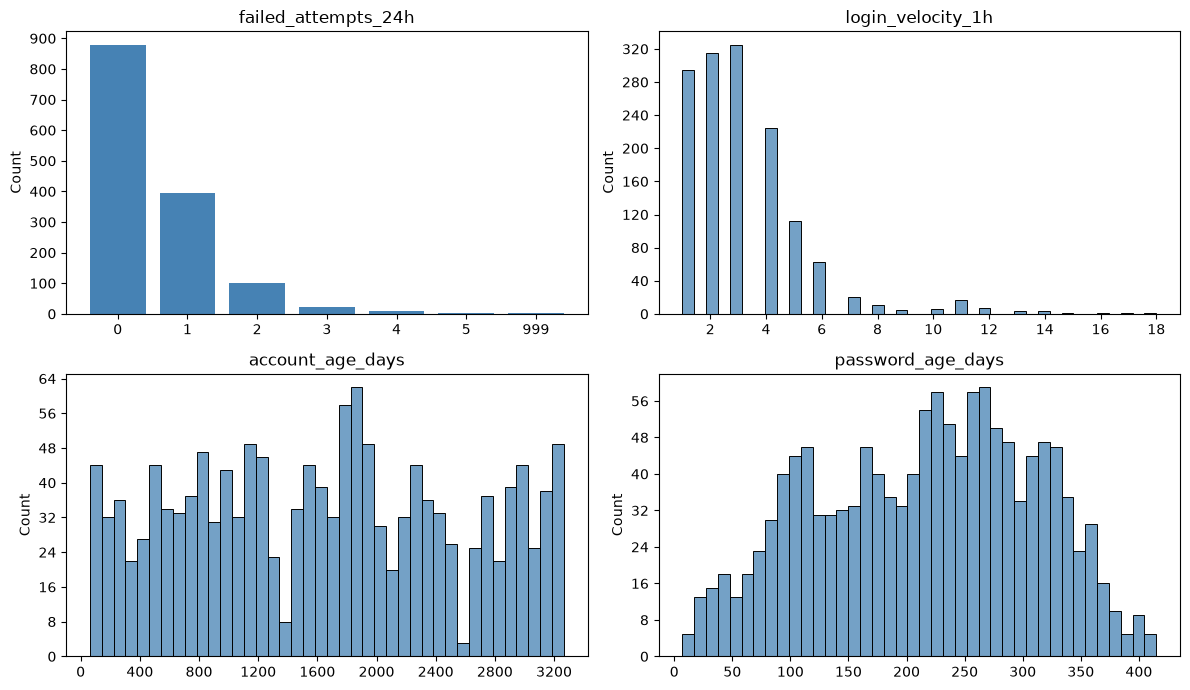

In [10]:
# ОТКРЫТЬ КОД
# ==========================================


OUTLIER_COLS = ['failed_attempts_24h', 'login_velocity_1h',
                'account_age_days', 'password_age_days']

outl = df[OUTLIER_COLS].apply(pd.to_numeric, errors='coerce')

# IQR
rows, iqr_masks = [], {}
for col in OUTLIER_COLS:
    s = outl[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_mask = (outl[col] < low) | (outl[col] > high)
    iqr_masks[col] = iqr_mask
    rows.append({
        'признак': col,
        'нижняя граница IQR': round(low, 2),
        'верхняя граница IQR': round(high, 2),
        'выбросов по IQR': int(iqr_mask.sum()),
        'доля IQR, %': round(iqr_mask.mean() * 100, 2),
    })

outlier_summary = pd.DataFrame(rows).set_index('признак')
display(outlier_summary)

# гистограммы
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, OUTLIER_COLS):
    if col == 'failed_attempts_24h':
        counts = outl[col].dropna().astype(int).value_counts().sort_index()
        ax.bar(counts.index.astype(str), counts.values, color='steelblue')
    else:
        sns.histplot(outl[col].dropna(), bins=40, ax=ax, color='steelblue')
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Count')
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()
plt.close(fig)


Выбросы по межквартильному размаху обнаружены в двух из четырёх признаков:
- В признаке failed_attempts_24h верхняя граница равна 2.5, поэтому выбросами считаются значения от 3 и выше: таких строк 34, что составляет 2.43% от всех данных. Основная масса значений лежит в диапазоне от 0 до 2. 
- В признаке login_velocity_1h верхняя граница равна 7.0, то есть выбросами считается более 7 входов в час: таких строк 57 (4.07%).
- В признаках account_age_days и password_age_days выбросов не обнаружено, так как границы IQR вышли за пределы максимальных и минимальных значений признака.
  
Отрицательные нижние границы у всех признаков являются следствием формулы Q1 - 1.5·IQR и не имеют физического смысла для счётчиков и возраста.
Правила обработки признаков:
- failed_attempts_24h: значения от 3 и выше оставляем, так как они могут означать подбор пароля. Значение 999 нереалистично для счётчика за сутки, поэтому считаем его скрытым пропуском.
- login_velocity_1h: значения выше 7 входов в час оставляем, так как такой всплеск может также означать подбор пароля.
- account_age_days и password_age_days: обработка не требуется.

In [11]:
# ОТКРЫТЬ КОД
# ==========================================
col = 'failed_attempts_24h'
df[col] = pd.to_numeric(df[col], errors='coerce')
print('failed_attempts_24h:')
mask_999 = df[col] == 999
n_999 = int(mask_999.sum())
print(f'Строк со значением 999: {n_999} ({n_999 / len(df) * 100:.2f}%)')
df.loc[mask_999, col] = np.nan
print(f'Заменено на NaN: {n_999}')
print(f'Пропусков в {col} после замены: {int(df[col].isna().sum())}')

failed_attempts_24h:
Строк со значением 999: 2 (0.14%)
Заменено на NaN: 2
Пропусков в failed_attempts_24h после замены: 5


# 7. Дисбаланс целевой переменной

,значение,количество,"доля, %"
класс,,,
0,нормальное событие (0),1286,91.08
1,подозрительное событие (1),126,8.92


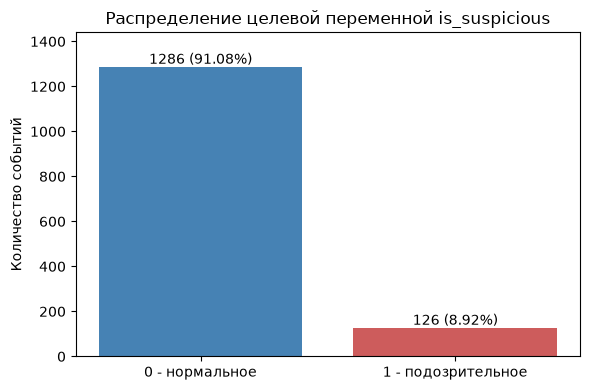

In [12]:
# ОТКРЫТЬ КОД
# ==========================================
TARGET = 'is_suspicious'

class_counts = df[TARGET].value_counts(dropna=False).sort_index()
class_share = (class_counts / class_counts.sum() * 100).round(2)

class_table = pd.DataFrame({
    'класс': class_counts.index,
    'значение': ['нормальное событие (0)' if v == 0 else 'подозрительное событие (1)'
                 for v in class_counts.index],
    'количество': class_counts.values,
    'доля, %': class_share.values,
}).set_index('класс')
display(class_table)

labels = ['0 - нормальное', '1 - подозрительное']
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, class_counts.values, color=['steelblue', 'indianred'])

# числовые значения над столбцами: количество и доля
for bar, cnt, share in zip(bars, class_counts.values, class_share.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f'{cnt} ({share}%)', ha='center', va='bottom')

ax.set_title('Распределение целевой переменной is_suspicious')
ax.set_ylabel('Количество событий')
ax.set_ylim(0, class_counts.max() * 1.12)
plt.tight_layout()
plt.show()
plt.close(fig)

Набор содержит 1412 событий: 1286 нормальных (91.08%) и 126 подозрительных (8.92%). Редким классом является класс 1, подозрительные события, соотношение классов около 10 : 1.
Направление дисбаланса соответствует реальной системе: большинство попыток аутентификации нормальные, а атаки редкие.
Accuracy - это метрика качества модели: какая доля всех предсказаний оказалась правильной. Обычная метрика Accuracy в дальнейшем может быть недостаточной, поскольку при дисбалансе классов модель может показывать высокую точность за счёт правильного определения большинства объектов основного класса, но при этом пропускать значительную часть подозрительных событий.

# 8. Поиск потенциальной утечки данных

Большинство признаков доступны в момент попытки аутентификации. Исключение составляют analyst_verdict и analyst_risk_score, поскольку они могут формироваться аналитиком после рассмотрения события.


In [13]:
# ОТКРЫТЬ КОД
# ==========================================
print("=== КОЛИЧЕСТВЕННАЯ ПРОВЕРКА ПРЯМОЙ УТЕЧКИ ===")
for col in ["analyst_verdict", "analyst_risk_score"]:
    print(f"\n--- {col} ---")
    table = pd.crosstab(df[col], df["is_suspicious"])
    display(table)
    accuracy = table.max(axis=1).sum() / table.to_numpy().sum() * 100
    print(f"Совпадение с целевой меткой: {accuracy:.2f}%")

=== КОЛИЧЕСТВЕННАЯ ПРОВЕРКА ПРЯМОЙ УТЕЧКИ ===

--- analyst_verdict ---


is_suspicious,0,1
analyst_verdict,,
benign,1286,0
confirmed_threat,0,126


Совпадение с целевой меткой: 100.00%

--- analyst_risk_score ---


is_suspicious,0,1
analyst_risk_score,,
3,23,0
4,19,0
5,21,0
6,20,0
7,22,0
8,19,0
9,15,0
10,13,0
11,23,0


Совпадение с целевой меткой: 100.00%


Поле event_id исключается из входных признаков, поскольку является уникальным идентификатором события и может приводить к запоминанию отдельных записей. Поле user_id используется только для группировки событий, так как модель может запоминать особенности конкретных пользователей. source_ip рекомендуется исключить или преобразовать, чтобы снизить риск запоминания конкретных IP-адресов. timestamp следует заменить производными признаками, например часом суток и признаком выходного дня, поскольку абсолютное время может плохо обобщаться на новые события.

Поля analyst_verdict и analyst_risk_score необходимо исключить, поскольку содержат результаты последующего анализа и могут приводить к утечке целевой переменной.

In [14]:
# ОТКРЫТЬ КОД
# ==========================================
print("=== ПРОВЕРКА ДУБЛИКАТОВ И СОБЫТИЙ ПОЛЬЗОВАТЕЛЕЙ ===")
duplicates = df.duplicated().sum()
print(f"Полных дубликатов строк: {duplicates}")

if "event_id" in df.columns:
    print(f"Повторяющихся event_id: {df['event_id'].duplicated().sum()}")

events_per_user = df.groupby("user_id", dropna=False).size()
print(f"Всего пользователей: {len(events_per_user)}")
print(f"Пользователей с несколькими событиями: {(events_per_user > 1).sum()}")

display(events_per_user[events_per_user > 1].sort_values(ascending=False).head(10))

=== ПРОВЕРКА ДУБЛИКАТОВ И СОБЫТИЙ ПОЛЬЗОВАТЕЛЕЙ ===
Полных дубликатов строк: 0
Повторяющихся event_id: 0
Всего пользователей: 120
Пользователей с несколькими событиями: 120


user_id
usr_062    23
usr_025    19
usr_082    19
usr_006    17
usr_060    17
usr_079    17
usr_020    17
usr_110    17
usr_113    17
usr_063    16
dtype: int64

Полных дубликатов строк и повторяющихся идентификаторов event_id не обнаружено. При этом все 120 пользователей имеют несколько событий аутентификации. Поэтому при случайном разделении данных по строкам события одного пользователя могут попасть одновременно в обучающую и тестовую выборки. Для корректной оценки способности модели выявлять подозрительную активность у новых пользователей необходимо выполнять разделение с группировкой по user_id, чтобы события одного пользователя находились только в одной выборке.

In [15]:
# ОТКРЫТЬ КОД
# ==========================================
print("\n=== РЕЕСТР ПОЛЕЙ ===")

registry_data = [
    # Идентификаторы и служебные поля
    ("event_id", "в момент события", "тех. идентификатор, 100% уникальных", "Нет", "исключить из X", "уникальный ключ записи, закономерностей не описывает, ведёт к запоминанию отдельных записей"),
    ("timestamp", "в момент события", "время, почти уникальное", "Нет", "исключить из X", "абсолютное время модель запомнит, а не обобщит; нужные производные (hour, is_weekend) уже есть в наборе"),
    ("user_id", "в момент события", "идентификатор объекта", "Нет", "исключить из X, использовать для GroupSplit", "риск запоминания конкретного пользователя; используется только как группа при разделении"),
    ("source_ip", "в момент события", "идентификатор источника, высокая кардинальность", "Нет", "исключить из X", "риск запоминания конкретных IP-адресов; сетевой контекст описывают country, new_country и vpn_used"),

    # Утечка из будущего
    ("analyst_verdict", "после расследования", "прямая утечка (кодирует метку, совпадение 100%)", "Нет", "исключить из X", "потенциальная утечка"),
    ("analyst_risk_score", "после расследования", "признак из будущего (разделяет классы)", "Нет", "исключить из X", "потенциальная утечка"),

    # Целевая переменная
    ("is_suspicious", "разметка", "целевая переменная", "Нет", "y", "метка класса: 1 - подозрительное событие, 0 - нормальное"),

    # Фокус варианта 2
    ("department", "до события", "категориальный, доступен заранее", "Да", "включить в X", "профиль пользователя"),
    ("auth_method", "в момент события", "категориальный", "Да", "включить в X", "способ входа"),
    ("failed_attempts_24h", "до события", "числовой счётчик", "Да", "включить в X", "индикатор подбора пароля"),
    ("login_velocity_1h", "до события", "числовой счётчик", "Да", "включить в X", "индикатор интенсивности попыток входа"),
    ("account_age_days", "до события", "числовой", "Да", "включить в X", "возраст аккаунта - часть профиля"),
    ("password_age_days", "до события", "числовой", "Да", "включить в X", "возраст пароля - часть профиля"),

    # Дополнительные признаки (вне фокуса варианта, доступны в момент попытки)
    ("country", "в момент события", "категориальный", "Нет", "включить в X", "страна, определённая по IP, доступна при попытке входа"),
    ("distance_from_usual_km", "в момент события", "числовой", "Нет", "включить в X", "расстояние от обычной геолокации известно при попытке входа"),
    ("new_country", "в момент события", "бинарный", "Нет", "включить в X", "признак входа из новой для пользователя страны"),
    ("vpn_used", "в момент события", "бинарный", "Нет", "включить в X", "факт использования VPN определяется при попытке входа"),
    ("device_type", "в момент события", "категориальный", "Нет", "включить в X", "тип устройства известен при попытке входа"),
    ("os_family", "в момент события", "категориальный", "Нет", "включить в X", "семейство ОС известно при попытке входа"),
    ("browser_family", "в момент события", "категориальный", "Нет", "включить в X", "семейство браузера известно при попытке входа"),
    ("known_device", "в момент события", "бинарный", "Нет", "включить в X", "знакомство системы с устройством известно при попытке входа"),
    ("hour", "в момент события", "производный от timestamp, не идентификатор", "Нет", "включить в X", "час суток обобщается на новые события, в отличие от абсолютного времени"),
    ("is_weekend", "в момент события", "производный от timestamp, не идентификатор", "Нет", "включить в X", "признак выходного дня обобщается на новые события"),
]

registry_df = pd.DataFrame(registry_data, columns=[
    "Поле",
    "Момент появления",
    "Тип риска",
    "Фокус анализа",
    "Решение",
    "Обоснование"
])

display(
    registry_df.style.set_properties(**{
        'text-align': 'center',
        'vertical-align': 'middle',
        'white-space': 'normal'
    }).set_table_styles([
        {'selector': 'th', 'props': [
            ('text-align', 'center'),
            ('vertical-align', 'middle'),
            ('white-space', 'normal')
        ]}
    ]).hide(axis='index')
)


=== РЕЕСТР ПОЛЕЙ ===


Поле,Момент появления,Тип риска,Фокус анализа,Решение,Обоснование
event_id,в момент события,"тех. идентификатор, 100% уникальных",Нет,исключить из X,"уникальный ключ записи, закономерностей не описывает, ведёт к запоминанию отдельных записей"
timestamp,в момент события,"время, почти уникальное",Нет,исключить из X,"абсолютное время модель запомнит, а не обобщит; нужные производные (hour, is_weekend) уже есть в наборе"
user_id,в момент события,идентификатор объекта,Нет,"исключить из X, использовать для GroupSplit",риск запоминания конкретного пользователя; используется только как группа при разделении
source_ip,в момент события,"идентификатор источника, высокая кардинальность",Нет,исключить из X,"риск запоминания конкретных IP-адресов; сетевой контекст описывают country, new_country и vpn_used"
analyst_verdict,после расследования,"прямая утечка (кодирует метку, совпадение 100%)",Нет,исключить из X,потенциальная утечка
analyst_risk_score,после расследования,признак из будущего (разделяет классы),Нет,исключить из X,потенциальная утечка
is_suspicious,разметка,целевая переменная,Нет,y,"метка класса: 1 - подозрительное событие, 0 - нормальное"
department,до события,"категориальный, доступен заранее",Да,включить в X,профиль пользователя
auth_method,в момент события,категориальный,Да,включить в X,способ входа
failed_attempts_24h,до события,числовой счётчик,Да,включить в X,индикатор подбора пароля


# 9. Выбор и выполнение разделения

In [16]:
# ОТКРЫТЬ КОД
# ==========================================
print("=== Отделение X от y и удаление утечек ===")
leak_cols = ['is_suspicious', 'event_id', 'timestamp', 'analyst_verdict', 'analyst_risk_score','source_ip']

y = df['is_suspicious']
groups = df['user_id']
X = df.drop(columns=leak_cols + ['user_id'])

print(f"В результате размер X: {X.shape}")

=== Отделение X от y и удаление утечек ===
В результате размер X: (1412, 16)


Варианты схем разделения:
- Стратифицированная случайная схема - случайное распределение событий с сохранением примерного соотношения классов. Недостаток заключается в том, что события одного пользователя могут попасть одновременно в обучающую и тестовую выборки.
- Групповая схема по user_id - все события одного пользователя относятся только к одной выборке. Это исключает пересечение пользователей и позволяет проверить способность модели обнаруживать подозрительную активность у пользователей, данные которых не использовались при обучении.
- Временная схема по timestamp - более ранние события используются для обучения, а более поздние - для тестирования. Она позволяет оценить способность модели выявлять подозрительную активность в будущих событиях, но не гарантирует отсутствия общих пользователей в обеих выборках.

В качестве основной выбрана групповая схема по user_id, поскольку задача заключается в обнаружении подозрительной активности у новых для модели пользователей. 

In [17]:
# ОТКРЫТЬ КОД
# ==========================================
# Групповое разделение
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print(f"X_train: {X_train.shape[0]} строк")
print(f"X_test:  {X_test.shape[0]} строк")

###########################################
train_users = set(groups_train.unique())
test_users = set(groups_test.unique())
intersection = train_users.intersection(test_users)

print(f"\nПользователей в train: {len(train_users)}")
print(f"Пользователей в test:  {len(test_users)}")
print(f"Пересечение: {len(intersection)}")

# Сравнение распределения y в train и test
train_dist = y_train.value_counts(normalize=True).sort_index()
test_dist = y_test.value_counts(normalize=True).sort_index()

compare_df = pd.DataFrame({
    'train (кол-во)': y_train.value_counts().sort_index(),
    'train (%)': (train_dist * 100).round(2),
    'test (кол-во)': y_test.value_counts().sort_index(),
    'test (%)': (test_dist * 100).round(2)
})
display(compare_df)

X_train: 1150 строк
X_test:  262 строк

Пользователей в train: 96
Пользователей в test:  24
Пересечение: 0


,train (кол-во),train (%),test (кол-во),test (%)
is_suspicious,,,,
0,1042,90.61,244,93.13
1,108,9.39,18,6.87


При групповом разделении данных по user_id получено 1150 строк в обучающей выборке (81,45%) и 262 строки в тестовой выборке (18,55%). Точное соотношение 80/20 по количеству строк не достигнуто, поскольку разделение выполняется по целым группам пользователей, имеющих различное количество событий. Все события одного пользователя должны находиться только в одной выборке: если часть событий попадёт в обучающую выборку, а другая часть - в тестовую, модель сможет использовать закономерности, связанные с уже встречавшимся пользователем.

# 10. Построение preprocessing pipeline

Для числовых признаков (failed_attempts_24h, login_velocity_1h, account_age_days, password_age_days, hour, distance_from_usual_km) предусмотрен двухшаговый конвейер: заполнение пропусков медианой, затем масштабирование RobustScaler.
Для категориальных признаков (department, auth_method, country, device_type, os_family, browser_family) пропуски заполняются наиболее частым значением, после чего применяется OneHotEncoder для преобразования категорий в числовые признаки.
Для бинарных признаков (is_weekend, known_device, new_country, vpn_used) пропуски заполняются наиболее частым значением без дополнительного масштабирования.

Признаки имеют разные масштабы: от 0-5 у failed_attempts_24h до тысяч у account_age_days, а многие модели чувствительны к масштабу и дают больший вес признакам с большими числами. Выбран RobustScaler, который вычитает медиану и делит на межквартильный размах. В отличие от StandardScaler, использующего среднее и стандартное отклонение, он почти не реагирует на выбросы. Это важно, так как в failed_attempts_24h и login_velocity_1h есть редкие большие значения, которые в данных ИБ могут быть самой атакой и поэтому не удаляются. StandardScaler исказил бы масштаб основной массы данных из-за этих хвостов.

Параметры заполнения и масштабирования (медианы и IQR) оцениваются только на обучающей выборке. Метод fit_transform состоит из двух шагов: fit запоминает параметры по данным, а transform применяет их к данным. На X_train вызывается fit_transform: параметры вычисляются по train и сразу применяются. К X_test применяется только transform: используются параметры, найденные по train, а свои медиана и IQR для test не считаются. Поэтому информация из тестовой части не попадает в обработку.

In [18]:
# ОТКРЫТЬ КОД
# ==========================================

numeric_features = ['failed_attempts_24h', 'login_velocity_1h', 'account_age_days',
                    'password_age_days', 'hour', 'distance_from_usual_km']
categorical_features = ['department', 'auth_method', 'country', 'device_type',
                        'os_family', 'browser_family']
binary_features = ['is_weekend', 'known_device', 'new_country', 'vpn_used']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  
    ('scaler', RobustScaler()) 
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), 
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)) 
])
binary_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features),
    ('bin', binary_transformer, binary_features),
])

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor)
])
X_train_processed = pipeline.fit_transform(X_train) # fit изучает параметры (медиану, моду, масштаб и категории), а transform применяет их
X_test_processed = pipeline.transform(X_test)  # только transform применяет уже изученные параметры

# 11. Проверка результата преобразования

In [19]:
# ОТКРЫТЬ КОД
# ==========================================
print(f"Размер X_train_ready: {X_train_processed.shape}")
print(f"Размер X_test_ready:  {X_test_processed.shape}")
print("\n=== Проверка количества строк ===")
print(f"Строк в y_train: {len(y_train)}")
print(f"Строк в y_test:  {len(y_test)}")

assert X_train_processed.shape[0] == len(y_train)
assert X_test_processed.shape[0] == len(y_test)

print("Количество строк совпадает с y_train и y_test.")
print("\n=== Названия результирующих признаков ===")
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()

print(f"Количество признаков: {len(feature_names)}")
print(feature_names)
print("\n=== Проверка NaN и бесконечностей ===")

for name, data in [
    ("X_train_ready", X_train_processed),
    ("X_test_ready", X_test_processed)
]:
    print(f"{name}:")
    print(f"  NaN: {np.isnan(data).sum()}")
    print(f"  Бесконечности: {np.isinf(data).sum()}")

    assert np.isfinite(data).all(), (
        f"В {name} найдены NaN или бесконечности"
    )
# Проверяем наличие categories_ где OneHotEncoder хранит категории
# найденные при обучении и использует их для преобразования данных
print("\n=== Проверка обучения ===")
print("Числовой преобразователь обучен:",
      hasattr(pipeline.named_steps['preprocessor']
              .named_transformers_['num'].named_steps['scaler'], 'center_'))

print("Категориальный преобразователь обучен:",
      hasattr(pipeline.named_steps['preprocessor']
              .named_transformers_['cat'].named_steps['onehot'], 'categories_'))

Path('artifacts').mkdir(exist_ok=True)
joblib.dump(pipeline, 'artifacts/preprocessor.joblib')

print("\nPipeline сохранён в artifacts/preprocessor.joblib")

Размер X_train_ready: (1150, 43)
Размер X_test_ready:  (262, 43)

=== Проверка количества строк ===
Строк в y_train: 1150
Строк в y_test:  262
Количество строк совпадает с y_train и y_test.

=== Названия результирующих признаков ===
Количество признаков: 43
['num__failed_attempts_24h' 'num__login_velocity_1h'
 'num__account_age_days' 'num__password_age_days' 'num__hour'
 'num__distance_from_usual_km' 'cat__department_Finance'
 'cat__department_HR' 'cat__department_IT' 'cat__department_Operations'
 'cat__department_R&D' 'cat__department_SOC' 'cat__department_Sales'
 'cat__auth_method_fido2' 'cat__auth_method_otp'
 'cat__auth_method_password' 'cat__auth_method_push' 'cat__country_BR'
 'cat__country_CN' 'cat__country_DE' 'cat__country_NL' 'cat__country_NO'
 'cat__country_PL' 'cat__country_RU' 'cat__country_SE' 'cat__country_US'
 'cat__device_type_desktop' 'cat__device_type_laptop'
 'cat__device_type_mobile' 'cat__device_type_tablet'
 'cat__os_family_Android' 'cat__os_family_Linux' 'cat__o

# 12. Итоговый аудит и выводы

## 12.1. Аудит

In [20]:
# ОТКРЫТЬ КОД
# ==========================================
raw = pd.read_excel(DATA_PATH, sheet_name='Data')   # исходные данные без очистки
raw_kept = raw.loc[df.index]                        # те же строки, что остались после удаления дубликатов

# ячейки, исправленные очисткой (было значение, стало NaN)
mask_fixed = raw_kept.notna() & df.isna()
mask_other = mask_fixed.copy()
mask_other.loc[raw_kept['failed_attempts_24h'] == 999, 'failed_attempts_24h'] = False   # 999 считаем отдельно

n_dup_removed = len(raw) - len(df)
n_fixed_other = int(mask_other.sum().sum())
rows_fixed_other = int(mask_other.any(axis=1).sum())

display(mask_fixed.sum()[mask_fixed.sum() > 0].rename('исправлено ячеек (значение → NaN)').to_frame())

# пропуски в признаках, которые идут в модель
model_cols = numeric_features + categorical_features
miss_cells = int(df[model_cols].isna().sum().sum())
miss_rows = int(df[model_cols].isna().any(axis=1).sum())

n_out_fail = int(outlier_summary.loc['failed_attempts_24h', 'выбросов по IQR'])
n_out_vel = int(outlier_summary.loc['login_velocity_1h', 'выбросов по IQR'])
n_susp = int(class_counts.loc[1])

# ---------- Итоговая таблица проблем ----------
audit = pd.DataFrame([
    ['Полные дубликаты строк',
     f'{n_dup_removed} лишних копий ({n_dup_removed / len(raw) * 100:.2f}%)',
     'Удалены (drop_duplicates), оставлена первая копия',
     n_dup_removed,
     'Копии одного события могли бы попасть и в train, и в test и завысить качество'],
    ['Заглушки и невозможные значения (unknown, "-", некорректные даты, отрицательные значения, пароль старше учётной записи)',
     f'{n_fixed_other} ячеек',
     'Заменены на NaN кодом, число исправлений посчитано',
     rows_fixed_other,
     'Без исправления искажали бы масштаб признаков и превращались бы в ложные категории'],
    ['Условное значение 999 в failed_attempts_24h',
     f'{n_999} строк ({n_999 / len(df) * 100:.2f}%)',
     'Заменено на NaN, заполняется медианой внутри pipeline',
     n_999,
     'Модель приняла бы 999 за экстремальный подбор пароля'],
    ['Пропуски в признаках модели',
     f'{miss_cells} ячеек в {miss_rows} строках',
     'Не удаляются, заполнение внутри pipeline (медиана, мода) по train',
     miss_rows,
     'Заполнение до разделения создало бы утечку из test'],
    ['Выбросы по IQR',
     f'failed_attempts_24h: {n_out_fail}; login_velocity_1h: {n_out_vel}',
     'Не удалены, масштабирование RobustScaler',
     n_out_fail + n_out_vel,
     'Могут быть самой атакой, удаление лишило бы модель сигнала'],
    ['Признаки утечки analyst_verdict, analyst_risk_score',
     'Совпадение с меткой 100%',
     'Исключены из X',
     len(df),
     'Появляются после разбора события, дали бы нереалистично высокое качество'],
    ['Идентификаторы и время (event_id, user_id, source_ip, timestamp)',
     '4 столбца',
     'Не используются как признаки, user_id только как группа',
     len(df),
     'Запоминание объектов вместо общей закономерности'],
    ['Связанные события одного пользователя',
     f'{df["user_id"].nunique()} пользователей, у всех несколько событий',
     'Групповое разделение по user_id',
     len(df),
     f'Пересечение групп train и test: {len(intersection)}, оценка не завышена запоминанием пользователей'],

], columns=['Проблема', 'Количественная оценка', 'Принятое решение', 'Затронуто объектов', 'Возможное влияние на модель'])

display(
    audit.style
    .set_properties(**{
        'text-align': 'center',
        'vertical-align': 'middle',
        'white-space': 'normal'
    })
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'center'),
                                     ('vertical-align', 'middle'),
                                     ('white-space', 'normal')]}
    ])
    .hide(axis='index')
)

# ---------- Сравнение исходного и подготовленного набора ----------
n_prep = X_train_processed.shape[0] + X_test_processed.shape[0]
comparison = pd.DataFrame({
    'Исходный набор': [
        len(raw), raw.shape[1], int(raw.isna().sum().sum()), int(raw.duplicated().sum()),
        f'{raw[TARGET].mean() * 100:.2f}%'],
    'После очистки': [
        len(df), df.shape[1], int(df.isna().sum().sum()), int(df.duplicated().sum()),
        f'{df[TARGET].mean() * 100:.2f}%'],
    'Подготовленные данные (train + test)': [
        n_prep, X_train_processed.shape[1],
        int(np.isnan(X_train_processed).sum() + np.isnan(X_test_processed).sum()), '—',
        f'{(y_train.sum() + y_test.sum()) / n_prep * 100:.2f}%'],
}, index=['Число объектов', 'Число признаков (столбцов)', 'Число пропусков (ячеек)',
          'Полных дубликатов', 'Доля класса 1 (is_suspicious)'])
display(
    comparison.style
    .set_properties(**{
        'text-align': 'center',
        'vertical-align': 'middle',
        'white-space': 'normal'
    })
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'center'),
                                     ('vertical-align', 'middle'),
                                     ('white-space', 'normal')]}
    ])
)

,исправлено ячеек (значение → NaN)
timestamp,4
department,8
browser_family,10
failed_attempts_24h,5
distance_from_usual_km,4
account_age_days,3
password_age_days,102


Проблема,Количественная оценка,Принятое решение,Затронуто объектов,Возможное влияние на модель
Полные дубликаты строк,18 лишних копий (1.26%),"Удалены (drop_duplicates), оставлена первая копия",18,"Копии одного события могли бы попасть и в train, и в test и завысить качество"
"Заглушки и невозможные значения (unknown, ""-"", некорректные даты, отрицательные значения, пароль старше учётной записи)",134 ячеек,"Заменены на NaN кодом, число исправлений посчитано",131,Без исправления искажали бы масштаб признаков и превращались бы в ложные категории
Условное значение 999 в failed_attempts_24h,2 строк (0.14%),"Заменено на NaN, заполняется медианой внутри pipeline",2,Модель приняла бы 999 за экстремальный подбор пароля
Пропуски в признаках модели,208 ячеек в 198 строках,"Не удаляются, заполнение внутри pipeline (медиана, мода) по train",198,Заполнение до разделения создало бы утечку из test
Выбросы по IQR,failed_attempts_24h: 34; login_velocity_1h: 57,"Не удалены, масштабирование RobustScaler",91,"Могут быть самой атакой, удаление лишило бы модель сигнала"
"Признаки утечки analyst_verdict, analyst_risk_score",Совпадение с меткой 100%,Исключены из X,1412,"Появляются после разбора события, дали бы нереалистично высокое качество"
"Идентификаторы и время (event_id, user_id, source_ip, timestamp)",4 столбца,"Не используются как признаки, user_id только как группа",1412,Запоминание объектов вместо общей закономерности
Связанные события одного пользователя,"120 пользователей, у всех несколько событий",Групповое разделение по user_id,1412,"Пересечение групп train и test: 0, оценка не завышена запоминанием пользователей"


,Исходный набор,После очистки,Подготовленные данные (train + test)
Число объектов,1430,1412,1412
Число признаков (столбцов),23,23,43
Число пропусков (ячеек),76,212,0
Полных дубликатов,18,0,—
Доля класса 1 (is_suspicious),9.02%,8.92%,8.92%


## 12.2. Выводы

In [21]:
# ОТКРЫТЬ КОД
# ==========================================
risks = pd.DataFrame([
    [
        'Риск качества данных',
        'В исходном наборе присутствуют пропуски, текстовые значения в числовых полях и отрицательные значения, не соответствующие предметному смыслу признаков.',
        'Некорректные числовые значения преобразуются в NaN. Пропуски заполняются внутри Pipeline с помощью SimpleImputer. Для категориальных признаков используется OneHotEncoder с handle_unknown="ignore".'
    ],
    [
        'Риск влияния выбросов',
        'Высокие значения failed_attempts_24h и login_velocity_1h могут быть как ошибками, так и проявлением атаки.',
        'Выбросы не удаляются автоматически. Для числовых признаков используется RobustScaler, менее чувствительный к крайним значениям.'
    ],
    [
        'Риск утечки данных',
        'analyst_verdict и analyst_risk_score формируются после события и могут напрямую раскрывать информацию о целевой метке.',
        'Эти признаки полностью исключены из X.'
    ],
    [
        'Риск запоминания пользователя',
        'Один пользователь имеет несколько событий, поэтому при обычном случайном разделении его события могли бы попасть одновременно в train и test.',
        'Используется GroupShuffleSplit по user_id. Пересечение пользователей между train и test равно 0.'
    ],
    [
        'Риск запоминания отдельных событий',
        'Полные дубликаты могли попасть в разные части выборки и сделать оценку модели искусственно лучше.',
        'Перед разделением данных удалены 18 полных дубликатов.'
    ],
    [
        'Риск ограниченной применимости результатов',
        'Датасет является синтетическим и содержит 1412 событий, поэтому полученные результаты нельзя напрямую переносить на реальные журналы аутентификации.',
        'При дальнейшей работе необходимо учитывать происхождение данных и дополнительно проверять модель на новых данных.'
    ]
], columns=[
    'Риск',
    'Описание и возможное влияние',
    'Мера контроля'
])

display(
    risks.style
    .set_properties(**{
        'text-align': 'center',
        'vertical-align': 'middle',
        'white-space': 'normal'
    })
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('text-align', 'center'),
                ('vertical-align', 'middle'),
                ('white-space', 'normal')
            ]
        },
        {
            'selector': 'td',
            'props': [
                ('min-width', '200px'),
                ('max-width', '450px')
            ]
        }
    ])
    .hide(axis='index')
)

Риск,Описание и возможное влияние,Мера контроля
Риск качества данных,"В исходном наборе присутствуют пропуски, текстовые значения в числовых полях и отрицательные значения, не соответствующие предметному смыслу признаков.","Некорректные числовые значения преобразуются в NaN. Пропуски заполняются внутри Pipeline с помощью SimpleImputer. Для категориальных признаков используется OneHotEncoder с handle_unknown=""ignore""."
Риск влияния выбросов,"Высокие значения failed_attempts_24h и login_velocity_1h могут быть как ошибками, так и проявлением атаки.","Выбросы не удаляются автоматически. Для числовых признаков используется RobustScaler, менее чувствительный к крайним значениям."
Риск утечки данных,analyst_verdict и analyst_risk_score формируются после события и могут напрямую раскрывать информацию о целевой метке.,Эти признаки полностью исключены из X.
Риск запоминания пользователя,"Один пользователь имеет несколько событий, поэтому при обычном случайном разделении его события могли бы попасть одновременно в train и test.",Используется GroupShuffleSplit по user_id. Пересечение пользователей между train и test равно 0.
Риск запоминания отдельных событий,Полные дубликаты могли попасть в разные части выборки и сделать оценку модели искусственно лучше.,Перед разделением данных удалены 18 полных дубликатов.
Риск ограниченной применимости результатов,"Датасет является синтетическим и содержит 1412 событий, поэтому полученные результаты нельзя напрямую переносить на реальные журналы аутентификации.",При дальнейшей работе необходимо учитывать происхождение данных и дополнительно проверять модель на новых данных.


В ходе подготовки датасета для классификации подозрительных событий аутентификации был проведён анализ качества исходных данных и устранены выявленные проблемы. Проверены пропуски, некорректные значения, полные дубликаты и выбросы. Некорректные значения, включая заглушки unknown и -, невозможные даты и отрицательные значения числовых признаков, были обработаны. Строки с пропусками в обязательных столбцах account_age_days, failed_attempts_24h и timestamp удаляются до разделения данных. Значение 999 в failed_attempts_24h рассматривается как специальное условное значение и заменяется на пропуск с последующим заполнением медианой в пайплайне.

Полные дубликаты удаляются, а выбросы анализируются без автоматического исключения, поскольку экстремальные значения могут указывать на подозрительную активность. Признаки analyst_verdict и analyst_risk_score, содержащие информацию, которая может появляться после анализа события, исключены из набора признаков во избежание утечки данных. Также не используются в качестве признаков идентификаторы событий, время и идентификатор пользователя. При этом user_id сохраняется отдельно для группового разделения данных.

Для формирования обучающей и тестовой выборок применяется GroupShuffleSplit с группировкой по user_id. Это позволяет исключить попадание событий одного пользователя одновременно в обе выборки и снизить риск завышения результатов из-за запоминания особенностей пользователей. Пропуски в оставшихся числовых признаках заполняются медианой, категориальные признаки - наиболее частыми значениями, а числовые данные масштабируются с помощью RobustScaler. Категориальные признаки преобразуются посредством OneHotEncoder. Все эти операции объединены в единый Pipeline: параметры преобразований обучаются только на тренировочной выборке, а к тестовой применяются без повторного обучения.

По результатам анализа датасет признан пригодным для последующей лабораторной работы по классификации угроз, поскольку после выполнения указанных процедур его можно использовать для обучения и оценки модели без очевидных нарушений порядка подготовки данных. Однако пригодность ограничена учебным экспериментом и соблюдением следующих условий:

- Очистка данных и удаление строк с пропусками в обязательных столбцах выполняются до разделения на обучающую и тестовую выборки.

- Заполнение пропусков, масштабирование и кодирование выполняются только внутри пайплайна, обучаемого на тренировочных данных.

- Выбросы не удаляются автоматически: необходимо учитывать их возможную связь с атаками и проверять подозрительные значения по источнику.

- Качество модели оценивается не только по accuracy, но и по precision, recall, F1-score и матрице ошибок, поскольку пропуск реальной угрозы может иметь существенные последствия.

- Перед применением в реальной системе необходимо проверить соответствие учебных данных реальному потоку событий, актуальность типов атак и стабильность распределений признаков.
